# Camera angle and posture classification: a pilot study
5 participants, 45 photos (3 postures x 3 camera views). Pose landmarks from MediaPipe, leave-one-person-out evaluation.
### Method
- **Data:** 5 volunteers (p01-p05), 3 postures (upright, slouched, lean) x 3 camera views (front, 45°, side) = 45 photos. Fixed phone position ([distance] m, [height]), plain wall, same setup for everyone.
- **Landmarks:** MediaPipe Pose Landmarker (heavy model): right ear, right shoulder, right hip.
- **Angles:** neck angle = angle of the ear-shoulder line from vertical; trunk angle = angle of the shoulder-hip line from vertical (image coordinates, degrees). Positive means the upper point is further right in the image; people face the right edge of the photo in the side view.
- **Classification:** logistic regression on [neck angle, trunk angle] after standardization; leave-one-person-out evaluation (train on 4 people, test on the 5th).

## 1. Setup
### 1.1 Install libraries

In [1]:
!pip install mediapipe opencv-python -q

### 1.2 Connect Google Drive and check the photos folder

In [2]:
from google.colab import drive
drive.mount('/content/drive')

!ls /content/drive/MyDrive/posture_study
!ls /content/drive/MyDrive/posture_study/photos | wc -l

Mounted at /content/drive
angles.csv  neck_angle_by_view.png  overlays  photos
45


### 1.3 Load the pose model and define helper functions

In [3]:
!wget -q -O pose_landmarker.task https://storage.googleapis.com/mediapipe-models/pose_landmarker/pose_landmarker_heavy/float16/latest/pose_landmarker_heavy.task

import os, cv2, numpy as np, pandas as pd, mediapipe as mp
from mediapipe.tasks import python as mp_python
from mediapipe.tasks.python import vision

BASE = "/content/drive/MyDrive/posture_study"
PHOTO_DIR = f"{BASE}/photos"
OVERLAY_DIR = f"{BASE}/overlays"
os.makedirs(OVERLAY_DIR, exist_ok=True)

detector = vision.PoseLandmarker.create_from_options(
    vision.PoseLandmarkerOptions(
        base_options=mp_python.BaseOptions(model_asset_path="pose_landmarker.task"),
        running_mode=vision.RunningMode.IMAGE))

def angle_from_vertical(top, bottom, w, h):
    dx = (top.x - bottom.x) * w
    dy = (bottom.y - top.y) * h
    return np.degrees(np.arctan2(dx, dy))

def analyze(path):
    name = os.path.basename(path)
    person, posture, view = name.rsplit(".", 1)[0].split("_")
    row = {"file": name, "person": person, "posture": posture, "view": view}
    img = cv2.imread(path)
    assert img is not None, f"Could not load {name}"
    h, w = img.shape[:2]
    result = detector.detect(mp.Image(image_format=mp.ImageFormat.SRGB,
                                      data=cv2.cvtColor(img, cv2.COLOR_BGR2RGB)))
    if not result.pose_landmarks:
        row.update(neck_angle=None, trunk_angle=None, min_visibility=None)
        return row
    lm = result.pose_landmarks[0]
    ear, sh, hip = lm[8], lm[12], lm[24]
    row.update(neck_angle=angle_from_vertical(ear, sh, w, h),
               trunk_angle=angle_from_vertical(sh, hip, w, h),
               min_visibility=min(ear.visibility, sh.visibility, hip.visibility))
    for p in (ear, sh, hip):
        cv2.circle(img, (int(p.x * w), int(p.y * h)), 18, (0, 0, 255), -1)
    cv2.imwrite(f"{OVERLAY_DIR}/{name}", cv2.resize(img, (600, int(600 * h / w))))
    return row

print("Setup done")

Setup done


## 2. Extract angles from photos
  
### 2.1 Run pose detection on all photos (saves angles.csv)

In [4]:
rows = [analyze(f"{PHOTO_DIR}/{f}") for f in sorted(os.listdir(PHOTO_DIR))
        if f.lower().endswith((".jpg", ".jpeg", ".png"))]
df = pd.DataFrame(rows).round(2)
df.to_csv(f"{BASE}/angles.csv", index=False)
print(len(df), "photos,", df["neck_angle"].isna().sum(), "with no detection")
df

45 photos, 0 with no detection


,file,person,posture,view,neck_angle,trunk_angle,min_visibility
0,p01_lean_45.jpeg,p01,lean,45,12.16,-16.62,1.0
1,p01_lean_front.jpeg,p01,lean,front,21.60,-6.59,1.0
2,p01_lean_side.jpeg,p01,lean,side,8.97,-12.92,1.0
3,p01_slouched_45.jpeg,p01,slouched,45,39.47,-0.10,1.0
4,p01_slouched_front.jpeg,p01,slouched,front,23.80,-8.00,1.0
5,p01_slouched_side.jpeg,p01,slouched,side,26.77,9.63,1.0
6,p01_upright_45.jpeg,p01,upright,45,23.83,-2.20,1.0
7,p01_upright_front.jpeg,p01,upright,front,24.73,-8.33,1.0
8,p01_upright_side.jpeg,p01,upright,side,10.48,1.31,1.0
9,p02_lean_45.jpeg,p02,lean,45,-7.74,-12.99,1.0


### 2.2 Check photos per person and missed detections

In [5]:
print(df.groupby("person").size())
print(df[df["neck_angle"].isna()][["file"]])

person
p01    9
p02    9
p03    9
p04    9
p05    9
dtype: int64
Empty DataFrame
Columns: [file]
Index: []


### 2.3 Check file names

In [6]:
import re
pattern = re.compile(r"^p\d{2}_(upright|slouched|lean)_(front|45|side)\.(jpe?g|png)$", re.I)
files = sorted(os.listdir(PHOTO_DIR))
bad = [f for f in files if not pattern.match(f)]
print(len(files), "files;", "bad names:", bad)
print(pd.Series([f[:3] for f in files]).value_counts().sort_index())

45 files; bad names: []
p01    9
p02    9
p03    9
p04    9
p05    9
Name: count, dtype: int64


## 3. Descriptive results

### 3.1 Mean neck and trunk angle by posture and view

In [7]:
df.pivot_table(index="posture", columns="view",
               values=["neck_angle", "trunk_angle"], aggfunc="mean").round(1)

neck_angle             trunk_angle           
view             45 front  side          45 front side
posture                                               
lean            5.6  24.9  -4.4       -14.3  -6.8 -9.6
slouched       42.1  28.9  26.7         4.5  -7.0  7.9
upright        22.0  25.2   8.2        -4.0  -6.6  0.4

### 3.2 Neck-angle mean and spread by posture and view

In [8]:
df.pivot_table(index="posture", columns="view", values="neck_angle",
               aggfunc=["mean", "std"]).round(1)

mean              std           
view        45 front  side   45 front side
posture                                   
lean       5.6  24.9  -4.4  7.9   2.9  8.6
slouched  42.1  28.9  26.7  6.2   3.9  5.1
upright   22.0  25.2   8.2  4.7   1.6  5.0

### 3.3 Figure: neck angle by view and posture

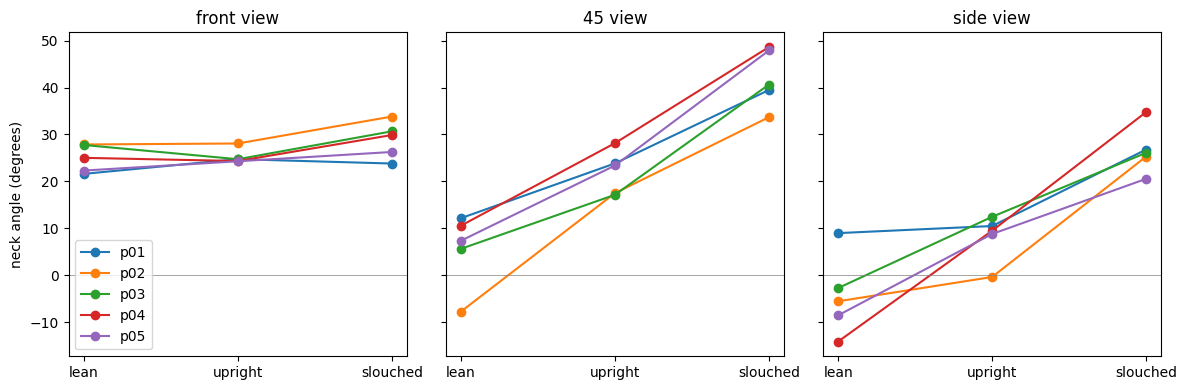

In [9]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharey=True)
order = ["lean", "upright", "slouched"]
for ax, view in zip(axes, ["front", "45", "side"]):
    for person, g in df[df.view == view].groupby("person"):
        g = g.set_index("posture").loc[order]
        ax.plot(order, g["neck_angle"], marker="o", label=person)
    ax.set_title(f"{view} view")
    ax.axhline(0, color="gray", lw=0.5)
axes[0].set_ylabel("neck angle (degrees)")
axes[0].legend()
plt.tight_layout()
plt.savefig(f"{BASE}/neck_angle_by_view.png", dpi=150)
plt.show()

## 4. Classification (leave-one-person-out)
### 4.1 Accuracy within each view

In [10]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import LeaveOneGroupOut, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

results = []
for view in ["side", "45", "front"]:
    d = df[df.view == view].dropna(subset=["neck_angle", "trunk_angle"])
    X, y = d[["neck_angle", "trunk_angle"]], d["posture"]
    model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
    pred = cross_val_predict(model, X, y, groups=d["person"], cv=LeaveOneGroupOut())
    results.append({"view": view, "n_photos": len(d), "accuracy": round((pred == y).mean(), 2)})
pd.DataFrame(results)

,view,n_photos,accuracy
0,side,15,1.00
1,45,15,1.00
2,front,15,0.27


### 4.2 Cross-view transfer (neck + trunk angle)

In [11]:
feats = ["neck_angle", "trunk_angle"]
rows = []
for train_view in ["side", "45"]:
    for test_view in ["side", "45", "front"]:
        correct, total = 0, 0
        for person in df.person.unique():
            tr = df[(df.view == train_view) & (df.person != person)].dropna(subset=feats)
            te = df[(df.view == test_view) & (df.person == person)].dropna(subset=feats)
            if len(tr) == 0 or len(te) == 0:
                continue
            m = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
            m.fit(tr[feats], tr["posture"])
            correct += (m.predict(te[feats]) == te["posture"]).sum()
            total += len(te)
        rows.append({"train": train_view, "test": test_view, "accuracy": round(correct / total, 2)})
pd.DataFrame(rows).pivot(index="train", columns="test", values="accuracy")

test,45,front,side
train,,,
45,1.00,0.33,0.73
side,0.87,0.60,1.00


### 4.3 Which angle transfers across views? (neck only vs trunk only)

In [12]:
def cross_view(feats):
    rows = []
    for train_view in ["side", "45"]:
        for test_view in ["side", "45", "front"]:
            correct, total = 0, 0
            for person in df.person.unique():
                tr = df[(df.view == train_view) & (df.person != person)].dropna(subset=feats)
                te = df[(df.view == test_view) & (df.person == person)].dropna(subset=feats)
                if len(tr) == 0 or len(te) == 0:
                    continue
                m = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
                m.fit(tr[feats], tr["posture"])
                correct += (m.predict(te[feats]) == te["posture"]).sum()
                total += len(te)
            rows.append({"train": train_view, "test": test_view, "accuracy": round(correct / total, 2)})
    return pd.DataFrame(rows).pivot(index="train", columns="test", values="accuracy")

print("neck only");  display(cross_view(["neck_angle"]))
print("trunk only"); display(cross_view(["trunk_angle"]))

neck only


test,45,front,side
train,,,
45,0.93,0.53,0.40
side,0.40,0.33,0.87


trunk only


test,45,front,side
train,,,
45,0.93,0.40,0.67
side,0.67,0.33,0.93


## 5. Failure case: hip landmark on the hand

In [14]:
hand_issue = ["p01_slouched_45.jpeg", "p03_lean_45.jpeg", "p03_slouched_45.jpeg",
              "p03_upright_45.jpeg", "p04_upright_45.jpeg", "p05_lean_45.jpeg"]

df["hip_on_hand"] = df["file"].isin(hand_issue)
df.to_csv(f"{BASE}/angles.csv", index=False)
print(df.groupby("view")["hip_on_hand"].sum())

df_all = df.copy()
df = df_all[~df_all["hip_on_hand"]].copy()      # leave out the 6 problem photos
print("45° photos left:", (df.view == "45").sum())
print("neck + trunk"); display(cross_view(["neck_angle", "trunk_angle"]))
print("trunk only");   display(cross_view(["trunk_angle"]))
df = df_all                                      # put everything back

view
45       6
front    0
side     0
Name: hip_on_hand, dtype: int64
45° photos left: 9
neck + trunk


test,45,front,side
train,,,
45,1.0,0.4,0.73
side,1.0,0.6,1.00


trunk only


test,45,front,side
train,,,
45,0.67,0.27,0.80
side,0.89,0.33,0.93


## 6. Summary and limitations

**Findings (5 participants, 45 photos, 3 postures x 3 camera views)**
- Side and 45° views: leave-one-person-out accuracy 1.00 (15 photos each). Front view: 0.27 (chance = 0.33).
- Front view: mean trunk angle is -6.8 / -7.0 / -6.6° for lean / slouched / upright, so it carries almost no posture information (hypothesis: forward lean is along the camera axis).
- Angles shift with camera view: mean upright neck angle is 8.2° (side) vs 22.0° (45°), so fixed thresholds do not transfer.
- Cross-view transfer (neck + trunk, train → test): side→45° 0.87, side→front 0.60, 45°→side 0.73, 45°→front 0.33.
- Side→45° by feature: neck only 0.40, trunk only 0.67, both 0.87.
- Hip landmark landed on the adjacent hand in 6 of 15 photos at 45° (found by visual inspection), none at front or side. Excluding them: side→45° 1.00 (neck + trunk) and 0.89 (trunk only); 45°→45° trunk only 0.93 → 0.67. With 9 photos left, differences of one or two photos are not meaningful.

**Limitations:** 5 participants, 15 photos per view, postures held on request, one pose model, one setting, no repeat photos, `min_visibility` was 1.0 for every photo (uninformative).